# Frozen V2: Windows evaluation
Development uses seed 42; fresh held-out seeds were predeclared in D37 before generation.
The exact source/configuration was frozen and committed before held-out execution.
All systems use the same saved input bytes, generator, scenarios and evaluator.
No tuning follows held-out exposure. Ground truth is interpreted only by the evaluator.
Response actions are recommendations. API keys come from the ignored local `.env`.

In [1]:
import asyncio, hashlib, json, os, pathlib, subprocess, sys
ROOT = pathlib.Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[name] = '1'
sys.path.insert(0, str(ROOT / 'src'))
from dotenv import load_dotenv
load_dotenv(ROOT / '.env', override=False)
from cyberagents.config import CONFIG
from cyberagents.pipeline import run_system, source_hash
from cyberagents.attack_kb import build_kb
from cyberagents.evaluate import evaluate_saved, render_results, render_a6_demo
from IPython.display import display, Image, Markdown
import pandas as pd
RUN = ROOT / 'outputs/evaluation_v2'
SEEDS = CONFIG['evaluation_seeds']
print('Development:', SEEDS[0], 'Held-out:', SEEDS[1:])
print('Model:', CONFIG['llm']['model'])


Development: 42 Held-out: [812399, 876694]
Model: gemini-3.5-flash-lite


## Frozen provenance and offline checks

In [2]:
freeze = json.loads((RUN / 'system_freeze.json').read_text())
assert freeze['source_hash'] == source_hash(), 'Frozen source/configuration changed'
tag = subprocess.check_output(['git', '-c', 'safe.directory=D:/agent', 'rev-parse',
                              'system-freeze-v2^{commit}'], text=True).strip()
print('Freeze decision:', freeze['decision_id'])
print('Source/configuration SHA256:', freeze['source_hash'])
print('Pre-evaluation Git commit:', tag)
checked = subprocess.run([sys.executable, '-m', 'pytest', '-m', 'not live', '-q'],
                         cwd=ROOT, text=True, capture_output=True)
print(checked.stdout.splitlines()[-1] if checked.stdout else checked.stderr)
if checked.returncode:
    print(checked.stdout, checked.stderr)
    raise RuntimeError('Offline suite failed')
kb = build_kb()


Freeze decision: D38
Source/configuration SHA256: d6ab1afbe2917d6f187c59be3551859dbf19cb022e955eeb64c3f4612facd1a0
Pre-evaluation Git commit: a2e4246126737d9f124380ed949081dacca0bece


82 passed, 1 deselected, 26 warnings in 51.35s


## Development results (reported separately)

In [3]:
for system in ['S0', 'S1', 'S3']:
    output = await asyncio.to_thread(run_system, system, SEEDS[0], output_dir=RUN)
    metrics = evaluate_saved(RUN / f'{system}_seed{SEEDS[0]}.json', kb, output_dir=RUN)
    print(system, json.dumps({key: metrics[key] for key in [
        'detection_recall', 'mapping_accuracy', 'false_positives', 'a6_stages']}),
        'cached responses:', output.get('cache_hits', 0))


S0 {"detection_recall": 1.0, "mapping_accuracy": null, "false_positives": 11, "a6_stages": 2} cached responses: 0


S1 {"detection_recall": 0.3333333333333333, "mapping_accuracy": 0.6, "false_positives": 0, "a6_stages": 4} cached responses: 1


S3 {"detection_recall": 1.0, "mapping_accuracy": 0.9, "false_positives": 0, "a6_stages": 5} cached responses: 4


## Fresh held-out runs
Each new seed is generated by the freeze-protected pipeline on its first S0 run.
S1 and S3 then read those same saved files. Completed runs are reused on resume;
held-out runs are never forced. Incomplete coverage is retained and disclosed.

In [4]:
input_hashes = {}
for seed in SEEDS[1:]:
    print('Held-out seed:', seed, flush=True)
    for system in ['S0', 'S1', 'S3']:
        assert source_hash() == freeze['source_hash']
        output = await asyncio.to_thread(run_system, system, seed, output_dir=RUN, live=system != 'S0')
        paths = [RUN / f'seed{seed}' / name for name in [
            'auth.log', 'access.log', 'firewall.csv', 'asset_inventory.json']]
        current = {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in paths}
        if str(seed) in input_hashes:
            assert current == input_hashes[str(seed)], 'Systems received different inputs'
        input_hashes[str(seed)] = current
        expected = hashlib.sha256((source_hash() + ''.join(current[path.name] for path in paths)).encode()).hexdigest()
        assert output['fingerprint'] == expected
        metrics = evaluate_saved(RUN / f'{system}_seed{seed}.json', kb, output_dir=RUN)
        print(json.dumps({key: metrics[key] for key in ['system', 'seed', 'detection_recall',
            'mapping_accuracy', 'false_positives', 'a6_stages', 'runtime_s', 'llm_calls']}), flush=True)
        if system == 'S3':
            print('Coverage:', json.dumps(output['coverage']), flush=True)
(RUN / 'held_out_input_hashes.json').write_text(json.dumps(input_hashes, indent=2))


Held-out seed: 812399


{"system": "S0", "seed": 812399, "detection_recall": 1.0, "mapping_accuracy": null, "false_positives": 17, "a6_stages": 2, "runtime_s": 1.875, "llm_calls": 0}


{"system": "S1", "seed": 812399, "detection_recall": 0.3333333333333333, "mapping_accuracy": 0.6666666666666666, "false_positives": 0, "a6_stages": 5, "runtime_s": 13.938000000081956, "llm_calls": 1}


{"system": "S3", "seed": 812399, "detection_recall": 1.0, "mapping_accuracy": 0.9, "false_positives": 0, "a6_stages": 5, "runtime_s": 129.4529999999795, "llm_calls": 4}


Coverage: {"complete": true, "unresolved": {}}


...

{"system": "S0", "seed": 876694, "detection_recall": 1.0, "mapping_accuracy": null, "false_positives": 19, "a6_stages": 2, "runtime_s": 1.875, "llm_calls": 0}


{"system": "S1", "seed": 876694, "detection_recall": 0.5, "mapping_accuracy": 0.6666666666666666, "false_positives": 0, "a6_stages": 4, "runtime_s": 14.047000000020489, "llm_calls": 1}


{"system": "S3", "seed": 876694, "detection_recall": 1.0, "mapping_accuracy": 0.7, "false_positives": 0, "a6_stages": 4, "runtime_s": 132.6720000000205, "llm_calls": 5}


Coverage: {"complete": true, "unresolved": {}}


746

## Measured comparison and charts

,system,seed,detection_recall,incident_precision,false_positives,benign_case_false_positives,mapping_accuracy,a6_stages,nonexistent_technique_ids,unretrieved_technique_ids,invalid_evidence_refs,runtime_s,llm_calls,tokens
0,S0,42,1.000000,0.450000,11,5,NaN,2,0,NaN,0,1.703,0,0
3,S1,42,0.333333,1.000000,0,0,0.600000,4,0,NaN,0,1.704,0,0
6,S3,42,1.000000,1.000000,0,0,0.900000,5,0,0.0,0,78.375,0,0
1,S0,812399,1.000000,0.346154,17,5,NaN,2,0,NaN,0,1.875,0,0
4,S1,812399,0.333333,1.000000,0,0,0.666667,5,1,NaN,0,13.938,1,26418
7,S3,812399,1.000000,1.000000,0,0,0.900000,5,0,0.0,0,129.453,4,111057
2,S0,876694,1.000000,0.321429,19,5,NaN,2,0,NaN,0,1.875,0,0
5,S1,876694,0.500000,1.000000,0,0,0.666667,4,1,NaN,0,14.047,1,26876
8,S3,876694,1.000000,1.000000,0,0,0.700000,4,0,0.0,0,132.672,5,111514


,detection_recall,false_positives,mapping_accuracy,hallucination_rate,runtime_s
system,,,,,
S0,1.000000,18.0,NaN,0.000000,1.8750
S1,0.416667,0.0,0.666667,0.118056,13.9925
S3,1.000000,0.0,0.800000,0.000000,131.0625


Held-out summary: {"S0":{"detection_recall":1.0,"false_positives":18.0,"mapping_accuracy":null,"hallucination_rate":0.0,"runtime_s":1.875},"S1":{"detection_recall":0.4166666667,"false_positives":0.0,"mapping_accuracy":0.6666666667,"hallucination_rate":0.1180555556,"runtime_s":13.9925000001},"S3":{"detection_recall":1.0,"false_positives":0.0,"mapping_accuracy":0.8,"hallucination_rate":0.0,"runtime_s":131.0625}}


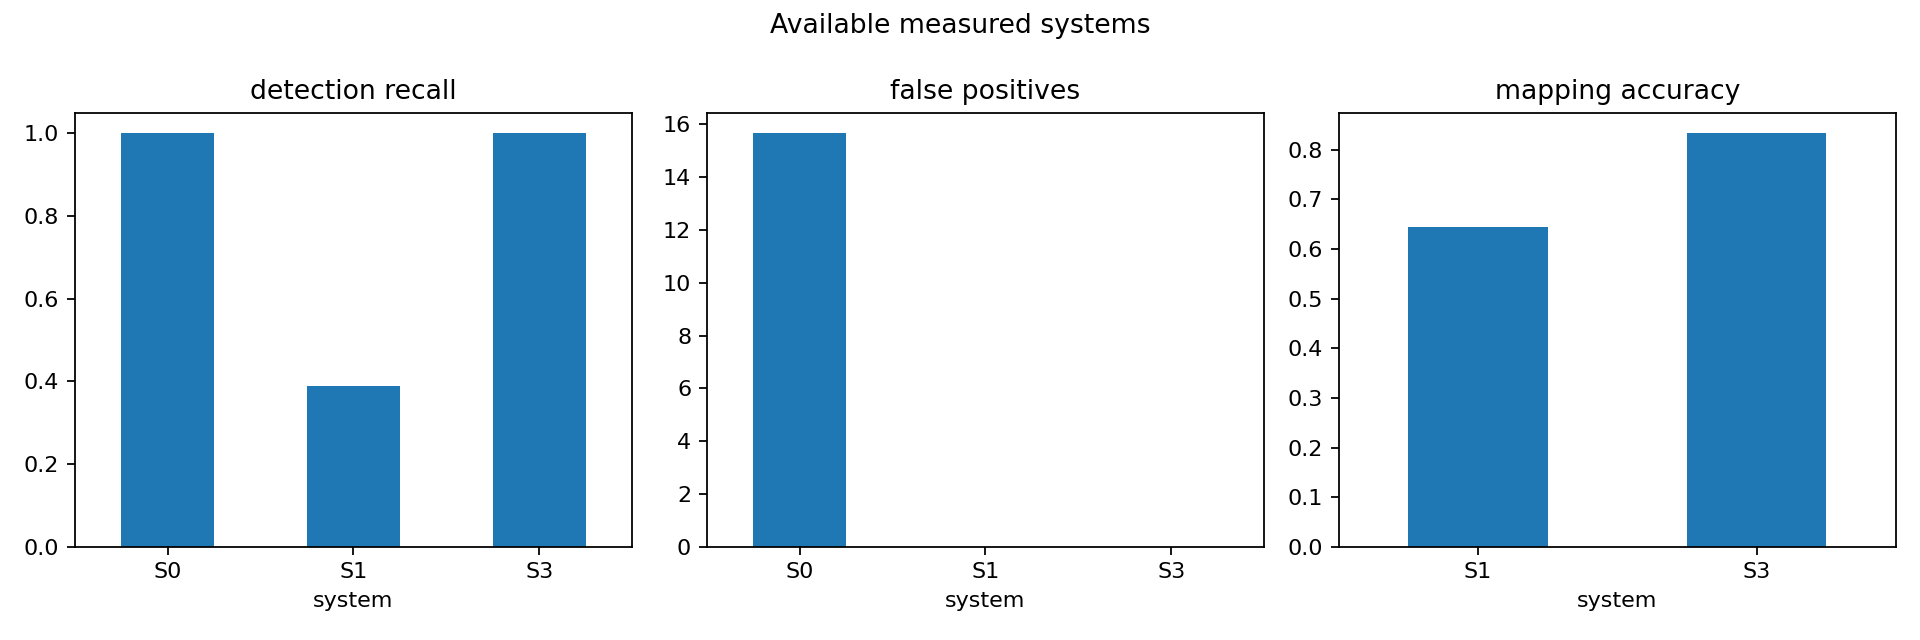

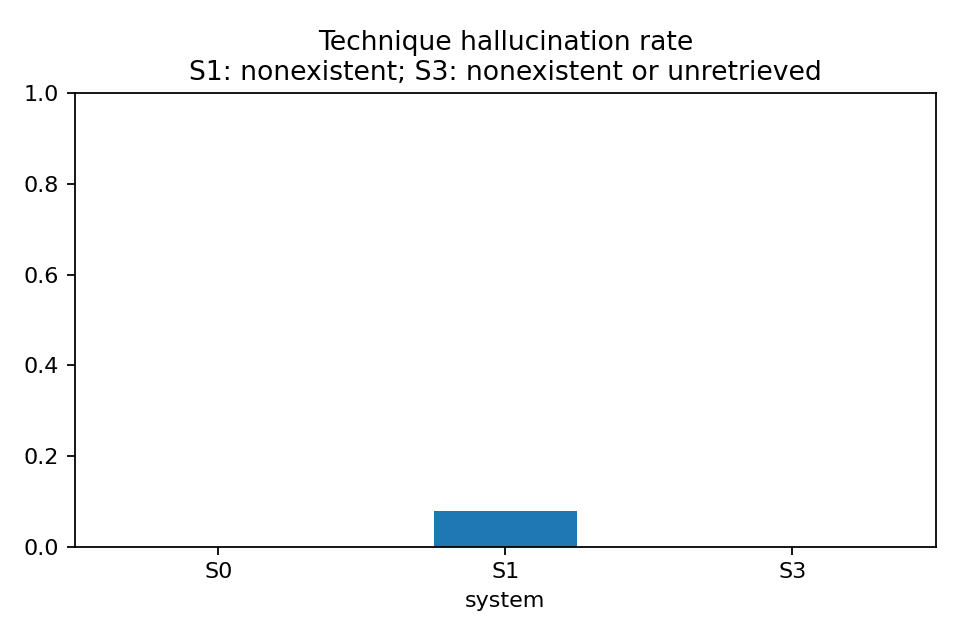

In [5]:
table = render_results(RUN)
columns = ['system', 'seed', 'detection_recall', 'incident_precision', 'false_positives',
    'benign_case_false_positives', 'mapping_accuracy', 'a6_stages', 'nonexistent_technique_ids',
    'unretrieved_technique_ids', 'invalid_evidence_refs', 'runtime_s', 'llm_calls', 'tokens']
display(table[columns].sort_values(['seed', 'system']))
held = table[table.seed.isin(SEEDS[1:])]
held.to_csv(RUN / 'held_out_results.csv', index=False)
summary = held.groupby('system')[['detection_recall', 'false_positives', 'mapping_accuracy',
    'hallucination_rate', 'runtime_s']].mean()
summary.to_csv(RUN / 'held_out_summary.csv')
display(summary)
print('Held-out summary:', summary.to_json(orient='index'))
display(Image(filename=str(RUN / 'comparison.png')))
display(Image(filename=str(RUN / 'hallucinations.png')))


## Error analysis and target checks

In [6]:
errors = pd.read_csv(RUN / 'error_analysis.csv')
display(errors)
target_rows = []
for row in table[table.system == 'S3'].to_dict('records'):
    seed = row['seed']
    output = json.loads((RUN / f'S3_seed{seed}.json').read_text())
    target_rows.append({'seed': seed, 'split': 'development' if seed == SEEDS[0] else 'held-out',
        'recall_target': row['detection_recall'] >= 5/6,
        'benign_fp_target': row['benign_case_false_positives'] <= 1,
        'mapping_target': row['mapping_accuracy'] >= .8,
        'a6_four_stages': row['a6_stages'] >= 4,
        'grounding_target': all(row[k] == 0 for k in [
            'invalid_evidence_refs', 'nonexistent_technique_ids', 'unretrieved_technique_ids']),
        'runtime_target': row['runtime_s'] <= 15*60,
        'coverage_complete': output['coverage']['complete']})
targets = pd.DataFrame(target_rows)
targets.to_csv(RUN / 'target_checks.csv', index=False)
display(targets)
print('S3 target checks:', targets.to_json(orient='records'))
print('A6 overall target met:', int(targets.a6_four_stages.sum()) >= 2)
print('Held-out false positives lower than S0:', summary.loc['S3', 'false_positives'] < summary.loc['S0', 'false_positives'])
print('Held-out mapping higher than S1:', summary.loc['S3', 'mapping_accuracy'] > summary.loc['S1', 'mapping_accuracy'])
print('Held-out hallucination lower than S1:', summary.loc['S3', 'hallucination_rate'] < summary.loc['S1', 'hallucination_rate'])


,system,seed,kind,item,matched_scenario,cause
0,S0,42,false_positive,s0-i1,B4,Benign/background evidence retained as an inci...
1,S0,42,false_positive,s0-i6,__background__,Benign/background evidence retained as an inci...
2,S0,42,false_positive,s0-i10,__background__,Benign/background evidence retained as an inci...
3,S0,42,false_positive,s0-i11,B1,Benign/background evidence retained as an inci...
4,S0,42,false_positive,s0-i12,B3,Benign/background evidence retained as an inci...
5,S0,42,false_positive,s0-i14,B2,Benign/background evidence retained as an inci...
6,S0,42,false_positive,s0-i15,__background__,Benign/background evidence retained as an inci...
7,S0,42,false_positive,s0-i17,__background__,Benign/background evidence retained as an inci...
8,S0,42,false_positive,s0-i18,__background__,Benign/background evidence retained as an inci...
9,S0,42,false_positive,s0-i19,__background__,Benign/background evidence retained as an inci...


,seed,split,recall_target,benign_fp_target,mapping_target,a6_four_stages,grounding_target,runtime_target,coverage_complete
0,42,development,True,True,True,True,True,True,True
1,812399,held-out,True,True,True,True,True,True,True
2,876694,held-out,True,True,False,True,True,True,True


S3 target checks: [{"seed":42,"split":"development","recall_target":true,"benign_fp_target":true,"mapping_target":true,"a6_four_stages":true,"grounding_target":true,"runtime_target":true,"coverage_complete":true},{"seed":812399,"split":"held-out","recall_target":true,"benign_fp_target":true,"mapping_target":true,"a6_four_stages":true,"grounding_target":true,"runtime_target":true,"coverage_complete":true},{"seed":876694,"split":"held-out","recall_target":true,"benign_fp_target":true,"mapping_target":false,"a6_four_stages":true,"grounding_target":true,"runtime_target":true,"coverage_complete":true}]
A6 overall target met: True
Held-out false positives lower than S0: True
Held-out mapping higher than S1: True
Held-out hallucination lower than S1: True


## A6 incident report from the first held-out run

In [7]:
try:
    report = render_a6_demo(RUN / f'S3_seed{SEEDS[1]}.json', RUN / 'demo_incident.md', output_dir=RUN)
    display(Markdown(report))
except ValueError as error:
    print(str(error))


# Compromise of SSH Server via Port Scan, Credential Access, Privilege Escalation, and Data Exfiltration

Synthetic-data demonstration; recommendations only.

Severity: critical | Confidence: 1.0

Critical multi-stage compromise of the SSH server originating from external IP 203.0.113.130, involving port scanning, credential guessing, successful SSH access using the 'deploy' account, privilege escalation to root via sudo, and data exfiltration to an external IP.

## Timeline

- 2026-10-16T20:43:06Z: T1595.001 — External source IP 203.0.113.130 performed sequential port scanning against the SSH server.
- 2026-10-16T20:53:06Z: T1110.001 — Initial failed password attempts from external IP 203.0.113.130 for user deploy.
- 2026-10-16T20:58:06Z: T1021.004 — Successful SSH session established after credential failures from an external IP address.
- 2026-10-16T21:00:06Z: T1548.003 — User deploy spawned /bin/bash as root via sudo following an externally sourced login session.
- 2026-10-16T21:13:06Z: T1041 — Large outbound transfer of 150,000,000 bytes to external suspicious IP 198.51.100.200 on port 4444.

## Recommended actions

- P1: Isolate SSH server and block attacker IP (target: 203.0.113.130)

```text
iptables -A INPUT -s 203.0.113.130 -j DROP
```

- P1: Block outbound exfiltration destination (target: 198.51.100.200)

```text
iptables -A OUTPUT -d 198.51.100.200 -j DROP
```

- P1: Terminate active compromised sessions (target: ssh-srv)

```text
pkill -u deploy
```


## ATT&CK mitigations

- M1056 Pre-compromise → T1595.001
- M1051 Update Software → T1110.001
- M1032 Multi-factor Authentication → T1110.001
- M1027 Password Policies → T1110.001
- M1036 Account Use Policies → T1110.001
- M1042 Disable or Remove Feature or Program → T1021.004
- M1032 Multi-factor Authentication → T1021.004
- M1018 User Account Management → T1021.004
- M1022 Restrict File and Directory Permissions → T1548.003
- M1028 Operating System Configuration → T1548.003
- M1026 Privileged Account Management → T1548.003
- M1031 Network Intrusion Prevention → T1041
- M1057 Data Loss Prevention → T1041

Evaluation: this incident covers 5 of the A6 stages.


## Saved report and preservation checks

In [8]:
def markdown_table(frame):
    rows = [list(frame.columns)] + frame.fillna('n/a').astype(str).values.tolist()
    return '\n'.join(['| ' + ' | '.join(rows[0]) + ' |',
        '| ' + ' | '.join(['---'] * len(rows[0])) + ' |'] +
        ['| ' + ' | '.join(row) + ' |' for row in rows[1:]])
report_text = ('# Frozen V2 evaluation on Windows\n\n'
    + 'Development seed: ' + str(SEEDS[0]) + '; fresh held-out seeds: ' + str(SEEDS[1:]) + '.\n\n'
    + 'Freeze decision: ' + freeze['decision_id'] + '; commit: ' + tag + '.\n\n'
    + 'Source/configuration SHA256: `' + source_hash() + '`.\n\n'
    + '## Per-seed measured results\n\n' + markdown_table(table[columns].sort_values(['seed', 'system']))
    + '\n\n## Held-out means (development excluded)\n\n' + markdown_table(summary.reset_index())
    + '\n\n## S3 target checks\n\n' + markdown_table(targets)
    + '\n\n## Errors\n\n' + markdown_table(errors)
    + '\n\n## Limits and reproducibility\n\n'
    + 'These are unseen draws from the same fixed synthetic generator, not real-world validation or new attack families. '
    + 'Mapping accuracy is conditional on detected scenarios/stages; compare recall alongside it. '
    + 'Development and held-out data are reported separately. Prompts, models, thresholds, evaluator and scenarios were fixed before held-out generation. '
    + 'No tuning or replacement seeds followed exposure. Existing identical provider responses may be reused; live-call counts and runtime are reported without claiming an uncached speedup. '
    + 'A zero hallucination score for both systems is a tie, not evidence that S3 beats S1. '
    + 'All response actions are recommendations. Original D33 and V2 development artifacts remain preserved.\n')
(RUN / 'report.md').write_text(report_text, encoding='utf-8')
manifest = json.loads((RUN / 'preservation_manifest.json').read_text())
for name, digest in manifest.items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest, name
assert source_hash() == freeze['source_hash']
print('Original artifacts, tests and evaluator preserved:', len(manifest))
print('Saved report:', str(RUN / 'report.md'))
print('Completed run files:', len(list(RUN.glob('S*_seed*.json'))))


Original artifacts, tests and evaluator preserved: 108
Saved report: D:\agent\outputs\evaluation_v2\report.md
Completed run files: 9


## Outcome and remaining semantic mapping errors

All nine S0/S1/S3 runs completed. S3 detects all six attacks with no false positives on both fresh seeds, but does not meet every target: seed 876694 has mapping accuracy 0.7, below the 0.8 per-seed target. The held-out mean is 0.8; it must not be presented as every seed passing. Notebook verification reports `82 passed, 1 deselected, 26 warnings in 51.35s` and all eight code cells completed.

| Fresh seed | S3 recall | S3 mapping accuracy | S3 false positives | A6 evidence stages |
|---|---|---|---|---|
| 812399 | 1.0 | 0.9 | 0 | 5 |
| 876694 | 1.0 | 0.7 | 0 | 4 |

On fresh seed 812399, finding `f-c008` describes an external port scan, while its primary technique is `T1595.002` (Vulnerability Scanning). The fixed A3 scenario accepts `T1046` or `T1595.001`. The saved run therefore has mapping accuracy 0.9 even though recall is 1.0 and grounding violations are zero.

This distinguishes valid, retrieved IDs from correct interpretation of observed behavior. The error is preserved in `S3_seed812399.json`; neither the accepted mappings nor the frozen system was changed after exposure. Passing the aggregate mapping target does not make every mapping correct.

On seed 876694, findings `f003` and `f009` describe port scans but choose the broader `T1595` (Active Scanning); the fixed accepted port-scan mappings are `T1046` or `T1595.001`. Finding `f004` combines failed and successful SSH authentication with primary `T1110` and secondary `T1133`; the successful-session stage instead accepts `T1078` or `T1021.004`. These are semantic mapping errors, not nonexistent or unretrieved IDs. The initial scan is a separate incident (`inc-002`), while `inc-003` joins authentication, privilege escalation and outbound transfer.

The unchanged evaluator's A6 metric measures stage evidence overlap within an incident, not the number of correct explicit technique steps. Seed 876694 has four such stages in its best-correlated incident; it does not present the entire five-stage chain together. Mapping accuracy separately penalizes incorrect primary choices.

Held-out S0 averages 18 false positives versus S3's 0. Held-out S1 averages detection_recall 0.41666666666666663 and mapping_accuracy 0.6666666666666666 versus S3's 1.0 and 0.8. S1 has one nonexistent technique ID on each fresh seed; S3 has zero nonexistent/unretrieved IDs and zero invalid evidence references. These results concern draws from the same synthetic generator, not real-world validation.

The comparison charts average all three declared seeds, including development; use held_out_summary.csv for fresh-data-only means. P19/P20 record the unresolved semantic errors. No tuning or held-out rerun followed exposure.
